In [11]:
import pandas as pd

In [13]:
data = pd.read_csv("/content/spotify_tracks.csv")

In [14]:
data = data.drop(columns=['artwork_url', 'track_url'])

In [15]:
#convert duration_ms into minutes
data['duration_min'] = data['duration_ms'] / 60000

In [16]:
hindi_data = data[data['language'] == 'Hindi']

In [17]:
print(hindi_data[['valence', 'energy', 'danceability']].describe())

           valence       energy  danceability
count  4652.000000  4652.000000   4652.000000
mean      0.506670     0.653091      0.589186
std       0.223607     0.191983      0.146416
min      -1.000000    -1.000000     -1.000000
25%       0.327000     0.512000      0.492750
50%       0.495000     0.665000      0.589000
75%       0.684000     0.808000      0.695000
max       0.983000     0.997000      0.939000


In [18]:
from scipy.stats import zscore

# Teeno features ko standardize karo (0-1 scale pe already hain, but z-score se comparable banao)
hindi_data['valence_z'] = zscore(hindi_data['valence'])
hindi_data['energy_z'] = zscore(hindi_data['energy'])
hindi_data['dance_z'] = zscore(hindi_data['danceability'])

# Combined mood score
hindi_data['mood_score'] = (hindi_data['valence_z'] + hindi_data['energy_z'] + hindi_data['dance_z']) / 3

# Ab is combined score ke quartiles nikaalo
sad_threshold = hindi_data['mood_score'].quantile(0.25)
party_threshold = hindi_data['mood_score'].quantile(0.75)
print(sad_threshold)
print(party_threshold)

def classify_mood(row):
    if row['mood_score'] <= sad_threshold:
        return 'Sad'
    elif row['mood_score'] >= party_threshold:
        return 'Party'
    else:
        return 'Neutral'

hindi_data['mood'] = hindi_data.apply(classify_mood, axis=1)

-0.6220638731639286
0.6431656298203429


/tmp/ipykernel_824/3236578808.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hindi_data['valence_z'] = zscore(hindi_data['valence'])
/tmp/ipykernel_824/3236578808.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hindi_data['energy_z'] = zscore(hindi_data['energy'])
/tmp/ipykernel_824/3236578808.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.

In [19]:
hindi_data

,track_id,track_name,artist_name,year,popularity,album_name,acousticness,danceability,duration_ms,energy,...,tempo,time_signature,valence,language,duration_min,valence_z,energy_z,dance_z,mood_score,mood
11,7qjOhCEl3pxRjJ2mHnfGrs,"Villain Kaun Hai (From ""Leo (Hindi)"")","Anirudh Ravichander, Manisha Eerabathini, Samp...",2024,34,"Villain Kaun Hai [From ""Leo (Hindi)""]",0.28000,0.684,185802.0,0.772,...,106.031,4.0,0.451,Hindi,3.096700,-0.248988,0.619436,0.647636,0.339362,Neutral
141,0JCcLshapR8UnPz8PwNP6x,"Badass (From ""Leo (Hindi)"")","Anirudh Ravichander, Raqueeb Alam, Hanuman",2023,45,"Badass [From ""Leo (Hindi)""]",0.02660,0.669,230741.0,0.863,...,93.016,4.0,0.486,Hindi,3.845683,-0.092447,1.093486,0.545177,0.515406,Neutral
149,2QwpIhEJmkGMDxK3XpNRFA,Lokiverse 2.0,Anirudh Ravichander,2023,27,Leo (Hindi) [Original Motion Picture Soundtrack],0.00069,0.641,114194.0,0.782,...,93.006,4.0,0.376,Hindi,1.903233,-0.584434,0.671530,0.353921,0.147005,Neutral
150,21htcSUXAaLkOg8a114IwQ,"Tera Hi Jaadu Hai (From ""Leo (Hindi)"")","Anirudh Ravichander, Raqueeb Alam, J.V. Sudhan...",2023,34,"Tera Hi Jaadu Hai [From ""Leo (Hindi)""]",0.74500,0.483,214330.0,0.572,...,83.881,4.0,0.541,Hindi,3.572167,0.153547,-0.422432,-0.725314,-0.331400,Neutral
155,1Dsg8ihIOw9ZWCL9v3gpt8,Bloody Sweet,"Anirudh Ravichander, Siddharth Basrur",2023,27,Leo (Hindi) [Original Motion Picture Soundtrack],0.00442,0.511,168540.0,0.683,...,123.850,4.0,0.254,Hindi,2.809000,-1.130092,0.155805,-0.534058,-0.502782,Neutral
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37318,6TjmF3JAgfkN1uMJ3ZOnsB,"Chaar Shanivaar (From ""All Is Well"")","Vishal Dadlani, Armaan Malik",2020,0,A Musical Tribute To Legendary Actor Rishi Kapoor,0.22000,0.501,214596.0,0.802,...,79.898,4.0,0.803,Hindi,3.576600,1.325371,0.775716,-0.602364,0.499574,Neutral
37325,0aUlD69H2ibHzfF7jxUA4s,"Fear Song (From ""Devara Part 1"") [Hindi]","Anirudh Ravichander, Manoj Muntashir",2024,46,"Fear Song (From ""Devara Part 1"") [Hindi]",0.03010,0.605,195094.0,0.883,...,180.024,4.0,0.455,Hindi,3.251567,-0.231098,1.197673,0.108019,0.358198,Neutral
37327,7ELXoDPvXqqeNbvVOED2Jh,"Jaago (From ""Hindustani 2"")","Anirudh Ravichander, Ritesh G Rao, Shruthika S...",2024,31,"Jaago (From ""Hindustani 2"")",0.22600,0.644,252436.0,0.921,...,116.963,4.0,0.311,Hindi,4.207267,-0.875153,1.395628,0.374412,0.298296,Neutral
38469,08W4EnE40TVdkIDNC2vcHz,"Dhaage (From ""Hindustani 2"")","Anirudh Ravichander, Manoj Muntashir, Abby V, ...",2024,30,"Dhaage (From ""Hindustani 2"")",0.01370,0.474,306000.0,0.736,...,139.873,4.0,0.472,Hindi,5.100000,-0.155063,0.431900,-0.786790,-0.169984,Neutral


In [22]:
hindi_data_clean = hindi_data.drop(columns=['valence_z', 'energy_z', 'dance_z', 'mood_score'])
hindi_data_clean.to_csv('hindi_songs_final.csv', index=False)

# from google.colab import files
# files.download('hindi_songs_final.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
hindi_data_clean.columns.tolist()

['track_id',
 'track_name',
 'artist_name',
 'year',
 'popularity',
 'album_name',
 'acousticness',
 'danceability',
 'duration_ms',
 'energy',
 'instrumentalness',
 'key',
 'liveness',
 'loudness',
 'mode',
 'speechiness',
 'tempo',
 'time_signature',
 'valence',
 'language',
 'duration_min',
 'mood']

In [24]:
print(hindi_data['mood'].value_counts())

mood
Neutral    2320
Party      1168
Sad        1164
Name: count, dtype: int64


In [25]:
# some "Sad" songs
hindi_data[hindi_data['mood'] == 'Sad'][['track_name', 'artist_name', 'valence', 'energy']].sample(5)



,track_name,artist_name,valence,energy
7810,"Murshida (From ""Begum Jaan"")","Arijit Singh, Anu Malik",0.499,0.432
7708,"Roke Na Ruke Naina (From ""Badrinath Ki Dulhania"")",Arijit Singh,0.264,0.382
15229,"In Dino (From ""Life In A Metro"")","Pritam, Soham",0.325,0.664
9206,Mehki Mehki Raatein,Javed Ali,0.512,0.520
8928,Milbu Tu Hamra Ke,Javed Ali,0.178,0.533


In [26]:
# some "Party" songs
hindi_data[hindi_data['mood'] == 'Party'][['track_name', 'artist_name', 'valence', 'energy']].sample(5)

,track_name,artist_name,valence,energy
14255,Sahibaa,"Pritam, Darshan Raval, Antara Mitra, Amitabh B...",0.668,0.953
15115,Harry's Not A Brahmachari (Version 2),"Pritam, Jaazy B, Divya Kumar, Ishq Bector",0.560,0.987
15117,Palang Tod,"Pritam, Ritu Pathak, Mika Singh",0.900,0.922
8897,Thakita Thakajham (Rock),Javed Ali,0.782,0.798
9152,Laqab Hai Laal Shahbaz Qalander,Ali Javed,0.923,0.799


In [27]:
trend = hindi_data.groupby(['year', 'mood']).size().unstack(fill_value=0)
print(trend)

mood  Neutral  Party  Sad
year                     
2000       11      2    3
2002        1      1    0
2003        1      1    0
2004        2      0    0
2005        1      0    2
2006        2      0    0
2007        2      1    0
2008        1      2    0
2009       25      2    4
2010       17     16    2
2011       88     73   15
2012       82     64   20
2013      117     66   31
2014       93     53   46
2015      112     54   50
2016      186     74   72
2017      228    114   93
2018      123     39   76
2019      176     67   78
2020      146     57   96
2021      133     53   98
2022      266    120  179
2023      392    251  225
2024      115     58   74


In [28]:
trend_clean = trend[trend.index >= 2010]

In [29]:
trend_pct = trend_clean.div(trend_clean.sum(axis=1), axis=0) * 100
print(trend_pct.round(1))

mood  Neutral  Party   Sad
year                      
2010     48.6   45.7   5.7
2011     50.0   41.5   8.5
2012     49.4   38.6  12.0
2013     54.7   30.8  14.5
2014     48.4   27.6  24.0
2015     51.9   25.0  23.1
2016     56.0   22.3  21.7
2017     52.4   26.2  21.4
2018     51.7   16.4  31.9
2019     54.8   20.9  24.3
2020     48.8   19.1  32.1
2021     46.8   18.7  34.5
2022     47.1   21.2  31.7
2023     45.2   28.9  25.9
2024     46.6   23.5  30.0


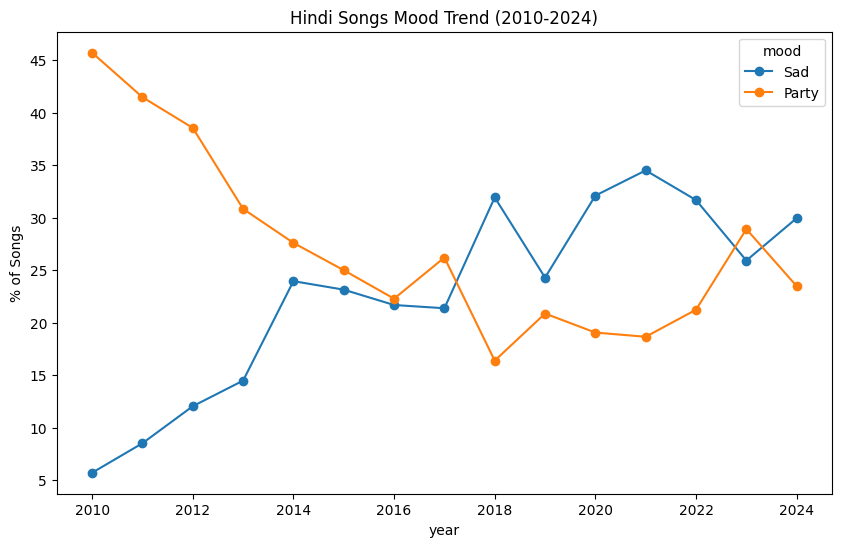

In [31]:
import matplotlib.pyplot as plt
trend_pct[['Sad', 'Party']].plot(kind='line', marker='o', figsize=(10,6))
plt.title('Hindi Songs Mood Trend (2010-2024)')
plt.ylabel('% of Songs')
plt.show()

In [35]:
# Columns that should be INTEGER in PostgreSQL
integer_columns = [
    "year",
    "popularity",
    "duration_ms",
    "key",
    "mode",
    "time_signature"
]

# Convert values like 7.0 → 7
for col in integer_columns:
    hindi_data_clean[col] = pd.to_numeric(hindi_data_clean[col], errors="coerce").round().astype("Int64")

print(hindi_data_clean[integer_columns].head())
print(hindi_data_clean[integer_columns].dtypes)

     year  popularity  duration_ms  key  mode  time_signature
11   2024          34       185802    7     0               4
141  2023          45       230741    3     0               4
149  2023          27       114194    1     1               4
150  2023          34       214330   10     1               4
155  2023          27       168540    5     1               4
year              Int64
popularity        Int64
duration_ms       Int64
key               Int64
mode              Int64
time_signature    Int64
dtype: object


In [37]:
# Save cleaned CSV
hindi_data_clean.to_csv("final_song_data", index=False)

# download dataset
from google.colab import files
files.download("final_song_data")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>